<a href="https://colab.research.google.com/github/upratik38-glitch/Portfolio_Pratik/blob/main/LSTM_Model_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


In [ ]:
data = np.sin(np.arange(500)*0.1).reshape(-1,1)

In [ ]:
scaler = MinMaxScaler()
data = scaler.fit_transform(data)

In [ ]:
X,y=[],[]
for i in range(10,len(data)):
    X.append(data[i-10:i])
    y.append(data[i])
X,y=np.array(X),np.array(y)

In [ ]:
split=int(0.8*len(X))
X_train,X_test=X[:split],X[split:]
y_train,y_test=y[:split],y[split:]

In [ ]:
model=Sequential([
    LSTM(50,input_shape=(10,1)),
    Dense(1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(optimizer='adam',loss='mse')

In [ ]:
model.fit(X_train,y_train,epochs=10,batch_size=32)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2419
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0564
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0391
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0333
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0300
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0280
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0263
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0247
Epoch 9/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0230
Epoch 10/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0211


In [ ]:
pred=model.predict(X_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


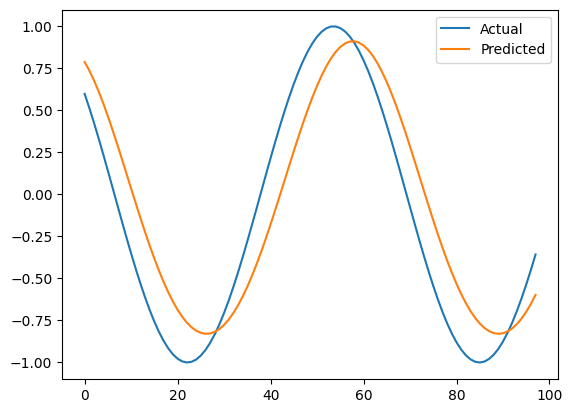

In [ ]:
plt.plot(scaler.inverse_transform(y_test),label='Actual')
plt.plot(scaler.inverse_transform(pred),label='Predicted')
plt.legend()
plt.show()